# Imports

In [17]:
import torchvision.datasets as dsets
import torchvision.transforms as transforms

from torch.utils.data import DataLoader
from torchvision.datasets import samplers
from pytorch_metric_learning import samplers

import matplotlib.pyplot as plt


# Transforms


In [2]:
trainingTransform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    ])

# Datasets

In [9]:
trainingDataset = dsets.ImageFolder(
    root='C:/Users/Robyn/Desktop/Research Project/imgs/Train',
    transform=trainingTransform
)
trainingDatasetTotalClasses = len(trainingDataset.classes)
trainingDatasetTotalImages = len(trainingDataset)
print( trainingDatasetTotalClasses, " Total Classes")
print(trainingDatasetTotalImages, "Total Images")




87  Total Classes
286 Total Images
[0, 0, 0, 1, 1, 1, 2, 2, 2, 3, 3, 3, 4, 4, 4, 5, 5, 5, 6, 6, 6, 7, 7, 7, 8, 8, 8, 9, 9, 9, 10, 10, 10, 10, 10, 11, 11, 11, 12, 12, 13, 13, 14, 14, 14, 15, 15, 15, 16, 16, 17, 17, 18, 18, 18, 18, 19, 19, 19, 19, 20, 20, 20, 20, 20, 20, 21, 21, 21, 21, 21, 21, 22, 22, 22, 23, 23, 23, 23, 23, 23, 23, 24, 24, 24, 24, 25, 25, 26, 26, 27, 27, 28, 28, 29, 29, 30, 30, 31, 31, 32, 32, 33, 33, 33, 33, 33, 34, 34, 35, 35, 36, 36, 37, 37, 37, 37, 38, 38, 39, 39, 40, 40, 41, 41, 41, 41, 42, 42, 42, 43, 43, 43, 44, 44, 44, 45, 45, 45, 45, 46, 46, 46, 46, 46, 46, 46, 46, 46, 47, 47, 48, 48, 49, 49, 49, 50, 50, 50, 51, 51, 51, 52, 52, 52, 53, 53, 54, 54, 55, 55, 55, 55, 55, 55, 55, 55, 55, 56, 56, 57, 57, 57, 57, 58, 58, 58, 59, 59, 59, 60, 60, 60, 60, 61, 61, 61, 61, 61, 62, 62, 62, 62, 62, 63, 63, 63, 63, 63, 64, 64, 64, 65, 65, 65, 66, 66, 66, 67, 67, 68, 68, 69, 69, 69, 69, 69, 70, 70, 70, 70, 70, 71, 71, 71, 71, 71, 71, 72, 72, 72, 72, 72, 73, 73, 73, 73, 74, 74

# Sampler

In [15]:
labels = trainingDataset.targets
mPerClass = 2

tripletSampler = samplers.MPerClassSampler(labels, mPerClass)

# Dataloaders


Feature batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])


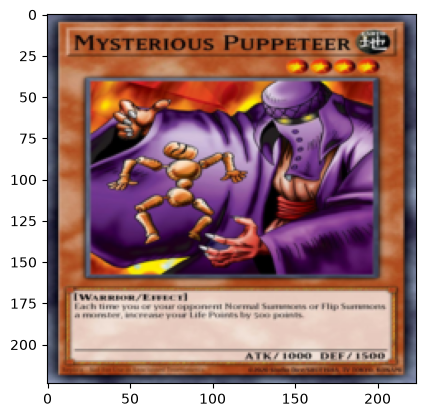

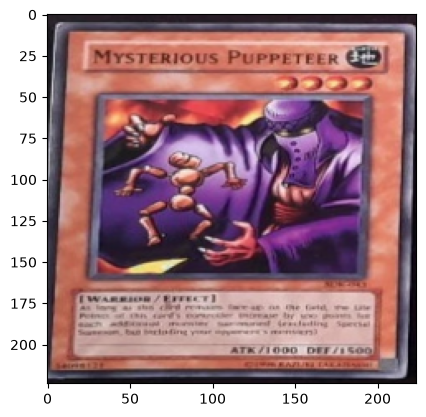

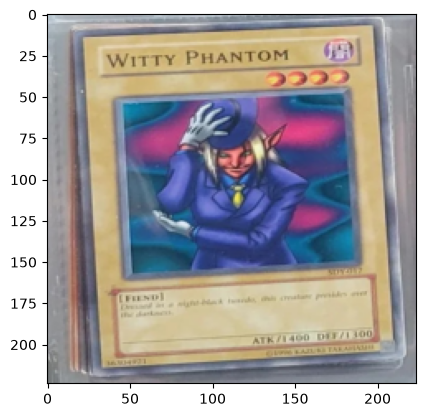

Label: 83


In [41]:
batchSize = 32
trainingDataLoader = DataLoader(
    trainingDataset,
    batchSize,
    sampler = tripletSampler)

trainFeatures, trainLabels = next(iter(trainingDataLoader))
print(f"Feature batch shape: {trainFeatures.size()}")
print(f"Label batch shape: {trainLabels.size()}")
img = trainFeatures[0].squeeze()
imgTwo = trainFeatures[1].squeeze()
imgThree = trainFeatures[2].squeeze()
label = trainLabels[0]
labelTwo = trainLabels[1]
labelThree = trainLabels[2]
plt.imshow(img.permute(1,2,0))
plt.show()
plt.imshow(imgTwo.permute(1,2,0))
plt.show()
plt.imshow(imgThree.permute(1,2,0))
plt.show()
print(f"Label: {label}")